# Experiment 6 — Linear Regression and Diagnostics (Titanic Dataset)

**Covers:** Multiple linear regression (OLS), correlation heatmap, coefficient table, R², adjusted R², MSE, RMSE, MAE, actual vs predicted, VIF, residual plots, Cook's distance and CSV export.

**Dataset:** **Titanic** – `train.csv` from the Kaggle Titanic competition ([kaggle.com/c/titanic](https://www.kaggle.com/competitions/titanic/data)), 891 passengers, columns `PassengerId, Survived, Pclass, Name, Sex, Age, SibSp, Parch, Ticket, Fare, Cabin, Embarked`.

**Data file:** keep `train.csv` in the **same folder as this notebook** (or replace the file name with its full path, e.g. `pd.read_csv(r"C:\Users\Lab\Desktop\train.csv")`).

**Remember:** OLS → Metrics → VIF → Residuals → Cook's Distance → Summary.

Target: `Fare` (continuous). This demonstrates regression diagnostics; it is not meant to be a strong fare-prediction model.

## Import libraries and load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor, OLSInfluence
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

df = pd.read_csv("train.csv")

## 1. Select data

             Fare         Age      Pclass       SibSp
count  714.000000  714.000000  714.000000  714.000000
mean    34.694514   29.699118    2.236695    0.512605
std     52.918930   14.526497    0.838250    0.929783
min      0.000000    0.420000    1.000000    0.000000
25%      8.050000   20.125000    1.000000    0.000000
50%     15.741700   28.000000    2.000000    0.000000
75%     33.375000   38.000000    3.000000    1.000000
max    512.329200   80.000000    3.000000    5.000000


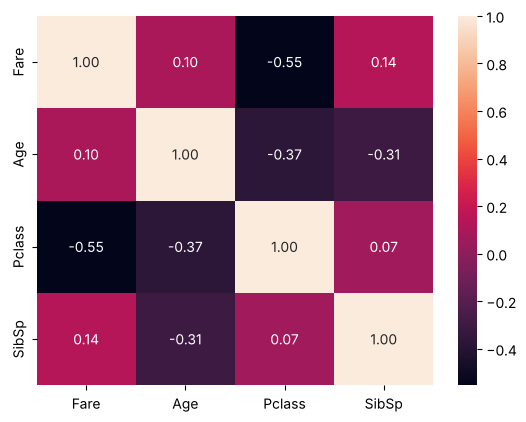

In [2]:
cols = ["Age", "Pclass", "SibSp"]
data = df[["Fare"] + cols].dropna()
print(data.describe())

sns.heatmap(data.corr(), annot=True, fmt=".2f")
plt.show()

X = data[cols]
y = data["Fare"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## 2. Linear regression (OLS)

In [3]:
model = sm.OLS(y_train, sm.add_constant(X_train)).fit()
print(model.summary())

coef = pd.DataFrame({
    "Coefficient": model.params,
    "Std Error": model.bse,
    "t": model.tvalues,
    "p": model.pvalues
})
print(coef)

                            OLS Regression Results                            
Dep. Variable:                   Fare   R-squared:                       0.408
Model:                            OLS   Adj. R-squared:                  0.404
Method:                 Least Squares   F-statistic:                     130.0
Date:                Wed, 28 Oct 2026   Prob (F-statistic):           4.39e-64
Time:                        11:08:32   Log-Likelihood:                -2889.2
No. Observations:                 571   AIC:                             5786.
Df Residuals:                     567   BIC:                             5804.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        120.2043      7.269     16.536      0.0

## 3. Predictions and evaluation

Train R2: 0.407500312832896
Adjusted R2: 0.4043653938531758
Test R2: 0.18618448729472836
MSE: 3388.1492554957017 RMSE: 58.20781094918191 MAE: 24.83089925924226


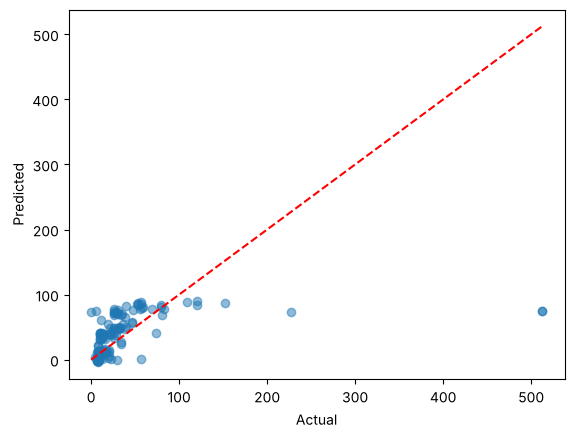

In [4]:
pred = model.predict(sm.add_constant(X_test))

mse = mean_squared_error(y_test, pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, pred)
r2 = r2_score(y_test, pred)

print("Train R2:", model.rsquared)
print("Adjusted R2:", model.rsquared_adj)
print("Test R2:", r2)
print("MSE:", mse, "RMSE:", rmse, "MAE:", mae)

plt.scatter(y_test, pred, alpha=0.5)
plt.plot([y.min(), y.max()], [y.min(), y.max()], "r--")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.show()

## 4. VIF (multicollinearity)
VIF > 5 → moderate, VIF > 10 → high multicollinearity.

  Feature       VIF
0     Age  1.258129
1  Pclass  1.160497
2   SibSp  1.092486


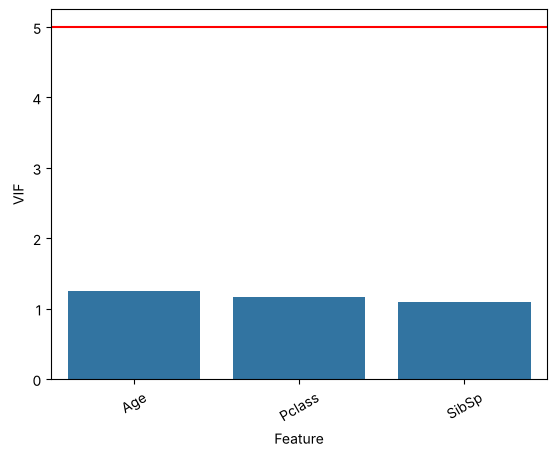

In [5]:
vif = pd.DataFrame({
    "Feature": cols,
    "VIF": [variance_inflation_factor(
        sm.add_constant(X_train).values, i + 1
    ) for i in range(len(cols))]
})
print(vif)

sns.barplot(data=vif, x="Feature", y="VIF")
plt.axhline(5, color="red")
plt.xticks(rotation=30)
plt.show()

## 5. Residual analysis

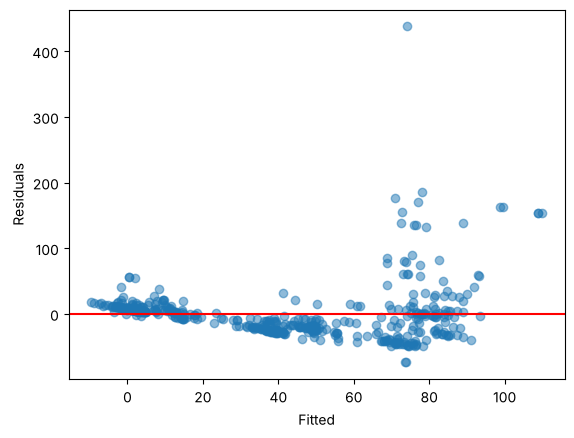

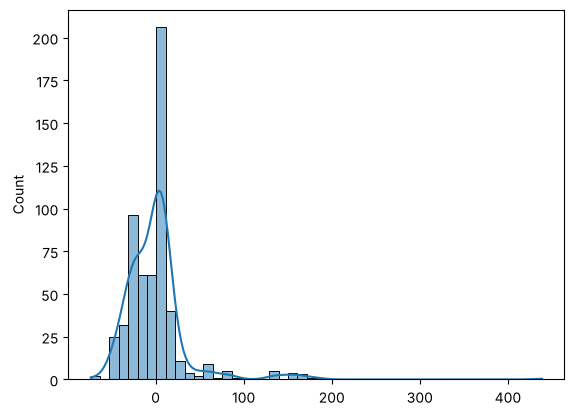

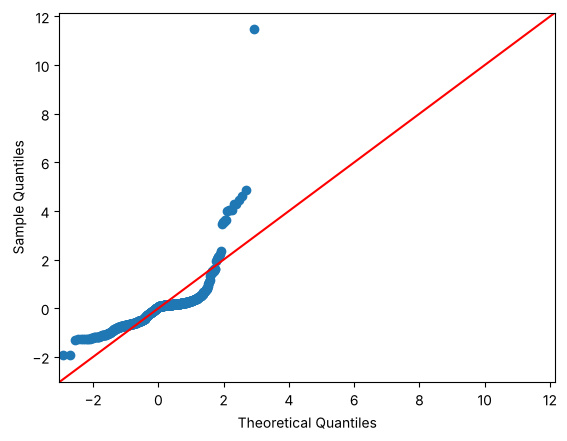

In [6]:
res = model.resid

plt.scatter(model.fittedvalues, res, alpha=0.5)
plt.axhline(0, color="red")
plt.xlabel("Fitted")
plt.ylabel("Residuals")
plt.show()

sns.histplot(res, kde=True)
plt.show()

sm.qqplot(res, line="45", fit=True)
plt.show()

## 6. Cook's distance (influential points)
Rule of thumb: Cook's D > 4/n is influential.

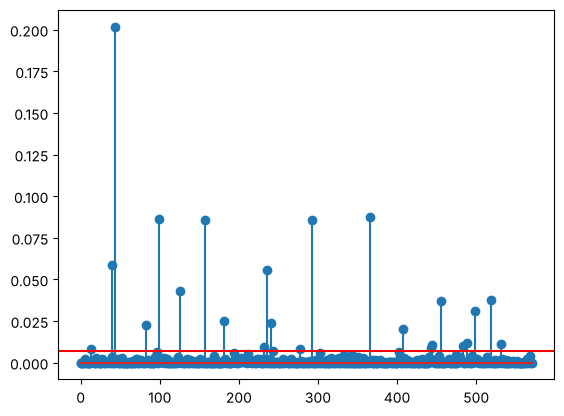

       Actual      Fitted    Residual  Std Residual   Cooks D
679  512.3292   74.200015  438.129185     11.485956  0.201826
438  263.0000   78.004585  184.995415      4.870548  0.087395
27   263.0000  109.901732  153.098268      4.043430  0.086345
341  263.0000  108.699356  154.300644      4.074163  0.085535
88   263.0000  108.939831  154.060169      4.067933  0.085522
311  262.3750   99.604328  162.770672      4.281198  0.058375
742  262.3750   98.882902  163.492098      4.298666  0.055575
118  247.5208   77.085718  170.435082      4.473524  0.042820
299  247.5208   70.833360  176.687440      4.634118  0.037743
689  211.3375   79.249996  132.087504      3.473522  0.037291


In [7]:
influence = OLSInfluence(model)
cooks = influence.cooks_distance[0]
limit = 4 / len(X_train)

plt.stem(range(len(cooks)), cooks)
plt.axhline(limit, color="red")
plt.show()

diagnostics = pd.DataFrame({
    "Actual": y_train,
    "Fitted": model.fittedvalues,
    "Residual": res,
    "Std Residual": influence.resid_studentized_internal,
    "Cooks D": cooks
})

print(diagnostics[diagnostics["Cooks D"] > limit].sort_values("Cooks D", ascending=False).head(10))

## 7. Summary and save

In [8]:
summary = pd.DataFrame({
    "Metric": ["Train R2", "Adjusted R2", "Test R2",
               "MSE", "RMSE", "MAE", "Max VIF", "Influential"],
    "Value": [model.rsquared, model.rsquared_adj, r2,
              mse, rmse, mae, vif["VIF"].max(), (cooks > limit).sum()]
})
print(summary)

coef.to_csv("coefficients.csv")
vif.to_csv("vif.csv", index=False)
diagnostics.to_csv("diagnostics.csv")
summary.to_csv("regression.csv", index=False)
print("Saved coefficients.csv, vif.csv, diagnostics.csv, regression.csv")

        Metric        Value
0     Train R2     0.407500
1  Adjusted R2     0.404365
2      Test R2     0.186184
3          MSE  3388.149255
4         RMSE    58.207811
5          MAE    24.830899
6      Max VIF     1.258129
7  Influential    24.000000
Saved coefficients.csv, vif.csv, diagnostics.csv, regression.csv


## Result / Conclusion
- Model: `Fare` ~ `Age` + `Pclass` + `SibSp` (714 passengers with known age). Each step down in class lowers the fare by about 37.3; each extra sibling/spouse adds about 10.5.
- Train R² = 0.408, but **test R² = 0.186** (RMSE 58.2) – fare is hard to predict with these features.
- VIF values are all about 1.1–1.3, so there is **no multicollinearity**.
- The residuals are strongly right-skewed (Q-Q plot bends upward). 24 influential points exceed 4/n; the largest is the 512.33 fare (Cook's D = 0.20).